# Causal DAGs

## Waffle

### Environment Setup

In [19]:
import pymc as pm
import arviz as az
import numpy as np
import scipy
import scipy.stats as stats
from scipy.optimize import minimize
import pandas as pd
import matplotlib.pyplot as plt
import numdifftools as nd
import pymc as pm
import arviz as az

### Data Load

In [20]:
data = pd.read_csv("WaffleDivorce.csv", sep=";")
waffle = data[["MedianAgeMarriage", "Marriage", "Divorce"]]
waffle

,MedianAgeMarriage,Marriage,Divorce
0,25.3,20.2,12.7
1,25.2,26.0,12.5
2,25.8,20.3,10.8
3,24.3,26.4,13.5
4,26.8,19.1,8.0
5,25.7,23.5,11.6
6,27.6,17.1,6.7
7,26.6,23.1,8.9
8,29.7,17.7,6.3
9,26.4,17.0,8.5


In [21]:
waffle.describe()

,MedianAgeMarriage,Marriage,Divorce
count,50.00000,50.000000,50.000000
mean,26.05400,20.114000,9.688000
std,1.24363,3.797905,1.820814
min,23.20000,13.500000,6.100000
25%,25.32500,17.125000,8.300000
50%,25.90000,19.700000,9.750000
75%,26.75000,22.100000,10.900000
max,29.70000,30.700000,13.500000


In [22]:
waffle.corr("pearson")

,MedianAgeMarriage,Marriage,Divorce
MedianAgeMarriage,1.000000,-0.721096,-0.597239
Marriage,-0.721096,1.000000,0.373731
Divorce,-0.597239,0.373731,1.000000


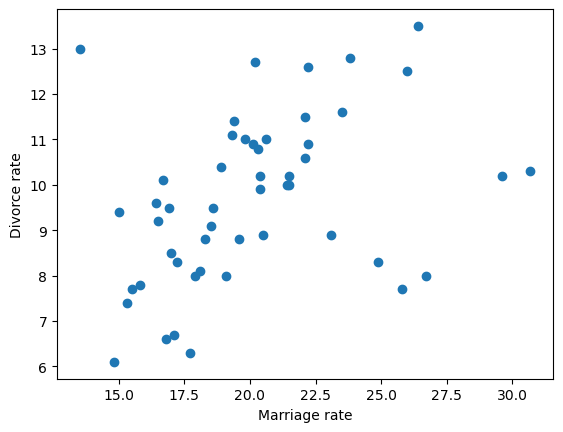

In [23]:
plt.scatter(waffle["Marriage"], waffle["Divorce"])
plt.xlabel("Marriage rate")
plt.ylabel("Divorce rate")
plt.show()

In [24]:
waffle["Marriage"] = (waffle["Marriage"] - waffle["Marriage"].mean()) / waffle[
    "Marriage"
].std()
waffle["Divorce"] = (waffle["Divorce"] - waffle["Divorce"].mean()) / waffle[
    "Divorce"
].std()
waffle["age"] = (
    waffle["MedianAgeMarriage"] - waffle["MedianAgeMarriage"].mean()
) / waffle["MedianAgeMarriage"].std()

waffle["Marriage"].mean()

np.float64(-1.127986593019159e-15)

### Model Preparation

In [25]:
m_i = waffle["Marriage"].to_numpy()
d_i = waffle["Divorce"].to_numpy()

with pm.Model() as model_m:
    alpha = pm.Normal("alpha", 0, 0.2)
    beta_m = pm.Normal("beta_m", 0, 0.5)
    sigma = pm.Exponential("sigma", 1)
    mu_i = alpha + beta_m * m_i
    divorce = pm.Normal("divorce", mu=mu_i, sigma=sigma, observed=d_i)

    trace_m = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_m, sigma]


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/usr/local/Caskroom/miniconda/base/envs/bayesian/lib/python3.11/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 15 seconds.


In [26]:
az.summary(trace_m, var_names=["alpha", "beta_m", "sigma"], hdi_prob=0.89)

,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,-0.001,0.111,-0.180,0.169,0.001,0.002,5519.0,3007.0,1.0
beta_m,0.348,0.131,0.153,0.562,0.002,0.002,5037.0,2442.0,1.0
sigma,0.950,0.098,0.803,1.110,0.001,0.002,4790.0,2867.0,1.0


<Axes: title={'center': 'beta_m'}>

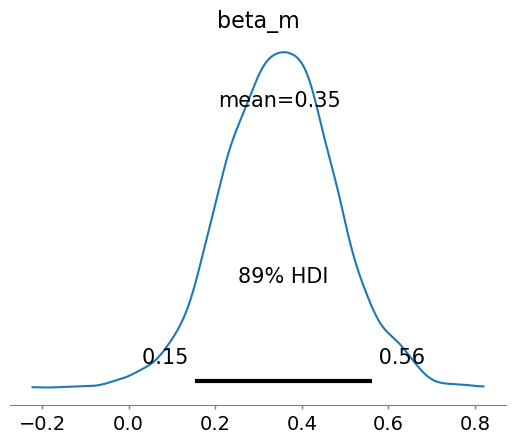

In [27]:
az.plot_posterior(trace_m, var_names=["beta_m"], hdi_prob=0.89)

In [34]:
a_i = waffle["age"].to_numpy()
d_i = waffle["Divorce"].to_numpy()

with pm.Model() as model_b:
    alpha = pm.Normal("alpha", 0, 0.2)
    beta_a = pm.Normal("beta_a", 0, 0.5)
    sigma = pm.Exponential("sigma", 1)
    mu_i = alpha + beta_a * a_i
    divorce = pm.Normal("divorce", mu=mu_i, sigma=sigma, observed=d_i)

    trace_a = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_a, sigma]


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/usr/local/Caskroom/miniconda/base/envs/bayesian/lib/python3.11/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 15 seconds.


In [35]:
az.summary(trace_a, var_names=["alpha", "beta_a", "sigma"], hdi_prob=0.89)

,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,-0.001,0.100,-0.151,0.166,0.001,0.002,6247.0,3114.0,1.0
beta_a,-0.564,0.118,-0.757,-0.381,0.002,0.002,4904.0,2953.0,1.0
sigma,0.821,0.084,0.684,0.945,0.001,0.001,5716.0,3274.0,1.0


<Axes: title={'center': 'beta_a'}>

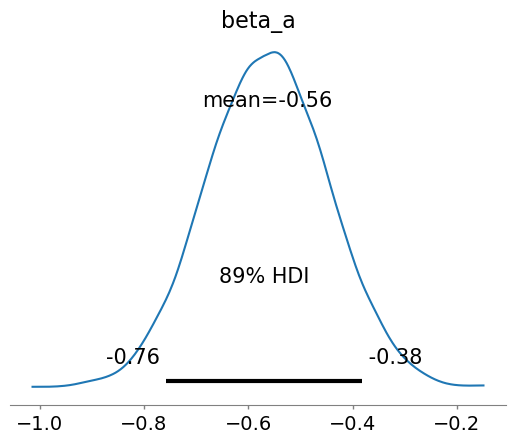

In [36]:
az.plot_posterior(trace_a, var_names=["beta_a"], hdi_prob=0.89)

In [37]:
a_i = waffle["age"].to_numpy()
m_i = waffle["Marriage"].to_numpy()
d_i = waffle["Divorce"].to_numpy()

with pm.Model() as model_c:
    alpha = pm.Normal("alpha", 0, 0.2)
    beta_m = pm.Normal("beta_m", 0, 0.5)
    beta_a = pm.Normal("beta_a", 0, 0.5)
    sigma = pm.Exponential("sigma", 1)
    mu_i = alpha + beta_a * a_i + beta_m * m_i
    divorce = pm.Normal("divorce", mu=mu_i, sigma=sigma, observed=d_i)

    trace_c = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_m, beta_a, sigma]


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/usr/local/Caskroom/miniconda/base/envs/bayesian/lib/python3.11/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 15 seconds.


In [38]:
az.summary(trace_c, var_names=["alpha", "beta_a", "beta_m", "sigma"], hdi_prob=0.89)

,mean,sd,hdi_5.5%,hdi_94.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,0.001,0.101,-0.149,0.171,0.002,0.002,3668.0,2908.0,1.0
beta_a,-0.608,0.156,-0.857,-0.364,0.003,0.003,2498.0,2596.0,1.0
beta_m,-0.063,0.157,-0.315,0.185,0.003,0.003,2414.0,2552.0,1.0
sigma,0.825,0.089,0.688,0.962,0.002,0.001,2951.0,2225.0,1.0


array([<Axes: title={'center': 'beta_a'}>,
       <Axes: title={'center': 'beta_m'}>], dtype=object)

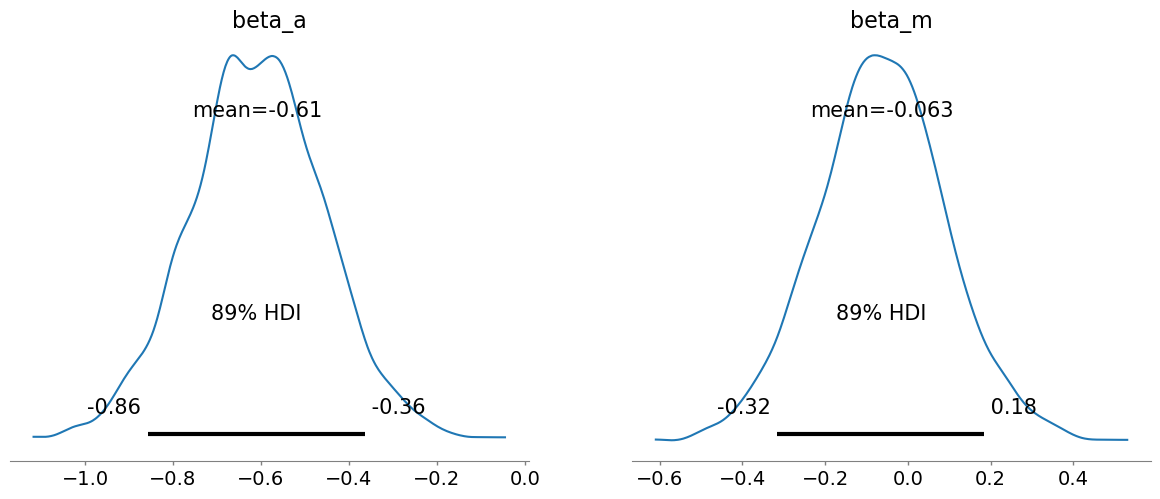

In [40]:
az.plot_posterior(trace_c, var_names=["beta_a", "beta_m"], hdi_prob=0.89)

/var/folders/5w/4gft5_wx579ct2wltm6v1r740000gn/T/ipykernel_6630/3728634305.py:15: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi_m = az.hdi(mu_m, hdi_prob=0.89)
/var/folders/5w/4gft5_wx579ct2wltm6v1r740000gn/T/ipykernel_6630/3728634305.py:16: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  hdi_c = az.hdi(mu_c, hdi_prob=0.89)


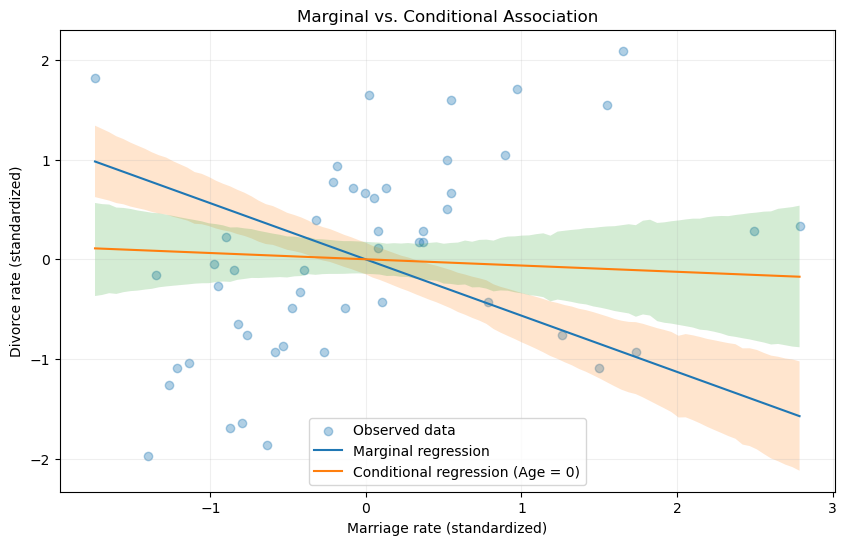

In [42]:
m_seq = np.linspace(m_i.min(), m_i.max(), 100)

alpha_m = trace_a.posterior["alpha"].values.flatten()
beta_m = trace_a.posterior["beta_a"].values.flatten()

alpha_c = trace_c.posterior["alpha"].values.flatten()
beta_c = trace_c.posterior["beta_m"].values.flatten()

mu_m = alpha_m[:, None] + beta_m[:, None] * m_seq[None, :]
mu_c = alpha_c[:, None] + beta_c[:, None] * m_seq[None, :]

mean_m = mu_m.mean(axis=0)
mean_c = mu_c.mean(axis=0)

hdi_m = az.hdi(mu_m, hdi_prob=0.89)
hdi_c = az.hdi(mu_c, hdi_prob=0.89)

plt.figure(figsize=(10, 6))

plt.scatter(m_i, d_i, alpha=0.35, label="Observed data")

plt.plot(m_seq, mean_m, label="Marginal regression")
plt.fill_between(m_seq, hdi_m[:, 0], hdi_m[:, 1], alpha=0.2)

plt.plot(m_seq, mean_c, label="Conditional regression (Age = 0)")
plt.fill_between(m_seq, hdi_c[:, 0], hdi_c[:, 1], alpha=0.2)

plt.xlabel("Marriage rate (standardized)")
plt.ylabel("Divorce rate (standardized)")
plt.title("Marginal vs. Conditional Association")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [46]:
a_i = waffle["age"].to_numpy()
m_i = waffle["Marriage"].to_numpy()

with pm.Model() as model_ma:
    alpha = pm.Normal("alpha", 0, 0.2)
    beta_a = pm.Normal("beta_a", 0, 0.5)
    sigma = pm.Exponential("sigma", 1)
    mu_m_i = alpha + beta_a * a_i
    marriage = pm.Normal("marriage", mu=mu_m_i, sigma=sigma, observed=m_i)

    trace_ma = pm.sample(draws=1000, tune=1000, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta_a, sigma]


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/usr/local/Caskroom/miniconda/base/envs/bayesian/lib/python3.11/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


/usr/local/Caskroom/miniconda/base/envs/bayesian/lib/python3.11/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 16 seconds.


In [48]:
alpha_mean = trace_ma.posterior["alpha"].mean().item()
beta_a_mean = trace_ma.posterior["beta_a"].mean().item()

predicted_m_i = alpha_mean + beta_a_mean * a_i
residual = m_i - predicted_m_i

In [50]:
print("Correlation with age:", np.corrcoef(residual, a_i)[0, 1])

print("Correlation with divorce:", np.corrcoef(residual, d_i)[0, 1])

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Correlation with age: -0.042926403819558076
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Correlation with divorce: -0.05646425101954169
